# Análisis bivariado (EPH): ¿qué factores se relacionan con tener PC e internet?
**Práctica Profesional I - Rita Josefina Juan Briones**

Análisis **bivariado** = analizar dos variables juntas (por ejemplo, nivel educativo y tener PC). Se ponen a prueba las tres hipótesis del proyecto. Se usa el archivo `df_clean.csv` generado en el cuaderno de limpieza (tiene que estar subido a Colab o creado en la misma sesión).

**Dos herramientas que vamos a usar:**
- **Tabla de contingencia:** cuenta cuántos hogares hay en cada combinación (por ejemplo, "primaria incompleta y sin PC").
- **Prueba chi-cuadrado:** dice si la relación entre dos variables de categorías es real o puede deberse al azar. Si el **valor p es menor a 0,05**, la relación es estadísticamente significativa. **V de Cramér** mide la fuerza (0 = nada, 1 = máxima; alrededor de 0,3 es una relación moderada).

## Paso 1: Cargar los datos limpios

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr, mannwhitneyu

try:
    df = pd.read_csv("df_clean.csv")
    print("Hogares:", len(df))
    print("Tienen PC:", round(df["TIENE_PC"].mean() * 100, 1), "% | Tienen internet fija:", round(df["TIENE_INTERNET"].mean() * 100, 1), "%")
except FileNotFoundError:
    print("No encuentro df_clean.csv. Subilo o ejecuta antes el cuaderno de limpieza.")

Hogares: 937
Tienen PC: 63.6 % | Tienen internet fija: 73.4 %


In [2]:
# Funcion auxiliar: prueba chi-cuadrado y V de Cramer a partir de una tabla de contingencia
def chi_cuadrado(tabla):
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    return chi2, gl, p, v

orden_ed = ["Primaria incompleta", "Primaria completa", "Secundaria incompleta",
            "Secundaria completa", "Superior/Univ. completo"]

## Estadísticas descriptivas de la base limpia
Antes de cruzar variables, se repiten las estadísticas de cada variable por separado (análisis univariado), ahora sobre la base ya limpia. `count` es la cantidad de datos válidos.

In [3]:
variables_clave = ["IX_TOT", "ITF"]

desc = df[variables_clave].agg(["mean", "median", "min", "max", "std"]).T
desc.columns = ["Media", "Mediana", "Minimo", "Maximo", "Desvio estandar"]
desc.insert(0, "Datos validos", df[variables_clave].count())
desc.round(2)

,Datos validos,Media,Mediana,Minimo,Maximo,Desvio estandar
IX_TOT,937,3.30,3.00,1.00,9.0,1.48
ITF,887,774289.33,602027.28,67038.89,5884802.3,585408.25


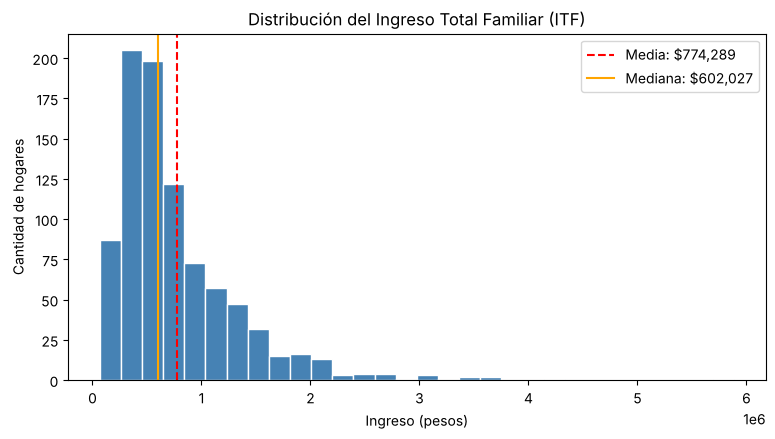

In [4]:
# Histograma del ingreso (sin los datos faltantes)
itf = df["ITF"].dropna()
plt.figure(figsize=(9, 4.5))
plt.hist(itf, bins=30, color="steelblue", edgecolor="white")
plt.axvline(itf.mean(), color="red", linestyle="--", label=f"Media: ${itf.mean():,.0f}")
plt.axvline(itf.median(), color="orange", label=f"Mediana: ${itf.median():,.0f}")
plt.title("Distribución del Ingreso Total Familiar (ITF)")
plt.xlabel("Ingreso (pesos)"); plt.ylabel("Cantidad de hogares"); plt.legend()
plt.show()

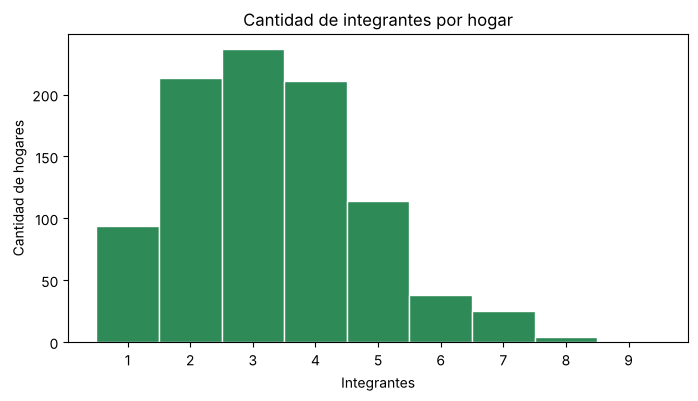

In [5]:
# Histograma de la cantidad de integrantes (cada barra es un valor entero)
plt.figure(figsize=(8, 4))
plt.hist(df["IX_TOT"], bins=np.arange(0.5, 10.5, 1), color="seagreen", edgecolor="white")
plt.title("Cantidad de integrantes por hogar")
plt.xlabel("Integrantes"); plt.ylabel("Cantidad de hogares"); plt.xticks(range(1, 10))
plt.show()

## Hipótesis 1: nivel educativo → tener PC e internet
**Paso 2:** porcentaje de hogares con PC e internet según el nivel educativo del jefe/a de hogar. (Se excluyen los hogares sin dato de educación.)
Como `TIENE_PC` vale 1 o 0, su **promedio** es directamente la proporción de hogares que tienen PC.

In [6]:
d1 = df.dropna(subset=["NIVEL_ED_NOM"])          # solo hogares con dato de educacion
print("Hogares analizados:", len(d1))

tabla_ed = (d1.groupby("NIVEL_ED_NOM")[["TIENE_PC", "TIENE_INTERNET"]].mean() * 100).reindex(orden_ed).round(1)
tabla_ed.columns = ["% con PC", "% con internet fija"]
tabla_ed

Hogares analizados: 921


,% con PC,% con internet fija
NIVEL_ED_NOM,,
Primaria incompleta,29.9,45.5
Primaria completa,49.5,61.7
Secundaria incompleta,62.8,71.1
Secundaria completa,75.4,84.8
Superior/Univ. completo,92.1,97.6


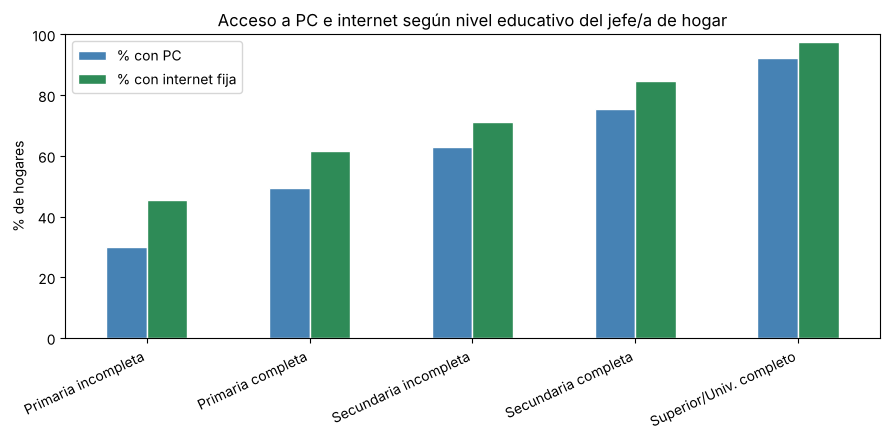

In [7]:
# Grafico de barras agrupadas
tabla_ed.plot(kind="bar", figsize=(9, 4.5), color=["steelblue", "seagreen"], edgecolor="white")
plt.title("Acceso a PC e internet según nivel educativo del jefe/a de hogar")
plt.ylabel("% de hogares"); plt.xlabel("")
plt.xticks(rotation=25, ha="right"); plt.ylim(0, 100)
plt.tight_layout(); plt.show()

In [8]:
# Prueba estadistica para PC y para internet
for var, nombre in [("TIENE_PC", "computadora"), ("TIENE_INTERNET", "internet fija")]:
    chi2, gl, p, v = chi_cuadrado(pd.crosstab(d1["NIVEL_ED_NOM"], d1[var]))
    rho, _ = spearmanr(d1["NIVEL_ED"], d1[var])
    print(f"{nombre}: chi2 = {chi2:.1f} (gl = {gl}), p = {p:.2g}, V de Cramer = {v:.2f}, correlacion de Spearman = {rho:.2f}")

computadora: chi2 = 112.7 (gl = 4), p = 1.9e-23, V de Cramer = 0.35, correlacion de Spearman = 0.34
internet fija: chi2 = 98.7 (gl = 4), p = 1.9e-20, V de Cramer = 0.33, correlacion de Spearman = 0.32


**Cómo se lee:** el acceso sube en cada escalón educativo. Con primaria incompleta tiene PC el ~30 % de los hogares y con estudios superiores el ~92 %. Como p es mucho menor a 0,05, **la relación no se debe al azar: la hipótesis 1 se confirma**.

## Hipótesis 2: ingreso → tener PC e internet
**Paso 3:** porcentaje de acceso por decil de ingreso. La **brecha** es la diferencia entre el decil 10 (más rico) y el decil 1 (más pobre), en puntos porcentuales (pp).

In [9]:
tabla_dec = (df.groupby("DECIFR")[["TIENE_PC", "TIENE_INTERNET"]].mean() * 100).round(1)
tabla_dec.columns = ["% con PC", "% con internet fija"]
print(tabla_dec)

brecha = tabla_dec.loc[10] - tabla_dec.loc[1]
print("\nBrecha decil 10 - decil 1 (puntos porcentuales):")
print(brecha.round(1))

        % con PC  % con internet fija
DECIFR                               
1           37.8                 59.2
2           44.6                 55.4
3           45.2                 61.3
4           67.0                 66.0
5           64.5                 62.4
6           67.4                 73.7
7           67.7                 79.6
8           71.6                 94.3
9           79.2                 87.5
10          91.6                 95.8

Brecha decil 10 - decil 1 (puntos porcentuales):
% con PC               53.8
% con internet fija    36.6
dtype: float64


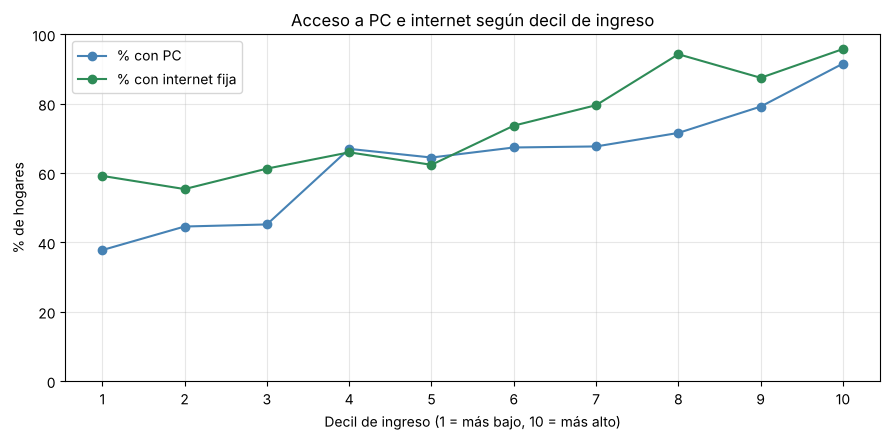

In [10]:
tabla_dec.plot(kind="line", marker="o", figsize=(9, 4.5), color=["steelblue", "seagreen"])
plt.title("Acceso a PC e internet según decil de ingreso")
plt.xlabel("Decil de ingreso (1 = más bajo, 10 = más alto)"); plt.ylabel("% de hogares")
plt.xticks(range(1, 11)); plt.ylim(0, 100); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [11]:
for var, nombre in [("TIENE_PC", "computadora"), ("TIENE_INTERNET", "internet fija")]:
    chi2, gl, p, v = chi_cuadrado(pd.crosstab(df["DECIFR"], df[var]))
    rho, _ = spearmanr(df["DECIFR"], df[var])
    print(f"{nombre}: chi2 = {chi2:.1f} (gl = {gl}), p = {p:.2g}, V de Cramer = {v:.2f}, correlacion de Spearman = {rho:.2f}")

computadora: chi2 = 102.7 (gl = 9), p = 4.4e-18, V de Cramer = 0.33, correlacion de Spearman = 0.32
internet fija: chi2 = 96.6 (gl = 9), p = 7.8e-17, V de Cramer = 0.32, correlacion de Spearman = 0.30


**Paso 4:** también se compara el **ingreso** (`ITF`) de los hogares que tienen y no tienen PC. Como el ingreso es muy asimétrico, se usa la **mediana** y la prueba de Mann-Whitney (que compara dos grupos sin suponer una forma de campana).

In [12]:
d2 = df.dropna(subset=["ITF"])           # solo hogares con dato de ingreso
print("Hogares analizados:", len(d2))

for var, nombre in [("TIENE_PC", "computadora"), ("TIENE_INTERNET", "internet fija")]:
    con = d2[d2[var] == 1]["ITF"]; sin = d2[d2[var] == 0]["ITF"]
    u, p = mannwhitneyu(con, sin)
    print(f"{nombre}: mediana del ingreso CON = ${con.median():,.0f} | SIN = ${sin.median():,.0f} | p = {p:.2g}")

Hogares analizados: 887
computadora: mediana del ingreso CON = $689,566 | SIN = $460,153 | p = 3e-19
internet fija: mediana del ingreso CON = $693,118 | SIN = $445,367 | p = 1.2e-20


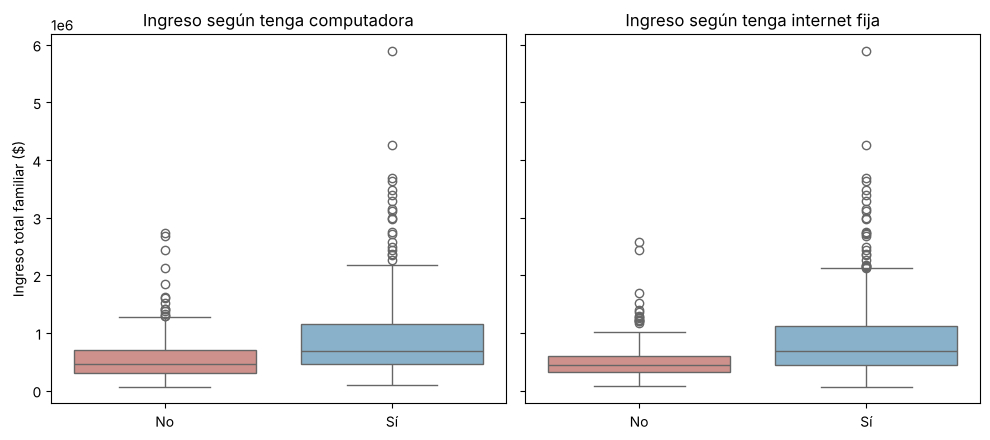

In [13]:
# Boxplots: ingreso segun tenga o no PC
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for eje, var, nombre in zip(ejes, ["TIENE_PC", "TIENE_INTERNET"], ["computadora", "internet fija"]):
    sns.boxplot(data=d2, x=var, y="ITF", ax=eje, palette=["#d98880", "#7fb3d5"], hue=var, legend=False)
    eje.set_xticks([0, 1]); eje.set_xticklabels(["No", "Sí"])
    eje.set_title(f"Ingreso según tenga {nombre}"); eje.set_xlabel(""); eje.set_ylabel("Ingreso total familiar ($)")
plt.tight_layout(); plt.show()

**Cómo se lee:** a mayor decil, mayor acceso. La brecha entre el decil 10 y el 1 es de unos **54 pp en computadora** y **37 pp en internet**. Los hogares con PC tienen una mediana de ingreso mucho mayor que los que no. **La hipótesis 2 se confirma.**

## Hipótesis 3: región (a igual ingreso) → internet fija
**Paso 5:** primero, el acceso a internet por región. Después, la comparación **dentro de cada grupo de ingreso**: GBA contra NOA y NEA. Así se controla el ingreso ("a igual ingreso").

In [14]:
# Acceso por region (en general)
tabla_reg = (df.groupby("REGION_NOM")[["TIENE_PC", "TIENE_INTERNET"]].mean() * 100).round(1)
tabla_reg.columns = ["% con PC", "% con internet fija"]
print(tabla_reg)

chi2, gl, p, v = chi_cuadrado(pd.crosstab(df["REGION_NOM"], df["TIENE_INTERNET"]))
print(f"\nInternet fija por region: chi2 = {chi2:.1f} (gl = {gl}), p = {p:.3f}, V de Cramer = {v:.2f}")

            % con PC  % con internet fija
REGION_NOM                               
Cuyo            59.8                 74.4
GBA             62.8                 73.6
NEA             66.2                 72.0
NOA             62.0                 72.1
Pampeana        66.7                 75.8
Patagonia       63.5                 72.9

Internet fija por region: chi2 = 0.7 (gl = 5), p = 0.982, V de Cramer = 0.03


In [15]:
# Comparacion GBA vs NOA+NEA dentro de cada grupo de ingreso
df["BLOQUE"] = np.where(df["REGION_NOM"] == "GBA", "GBA",
                np.where(df["REGION_NOM"].isin(["NOA", "NEA"]), "NOA+NEA", "Otras"))
d3 = df[df["BLOQUE"].isin(["GBA", "NOA+NEA"])]

filas = []
for grupo, sub in d3.groupby("GRUPO_INGRESO", observed=True):
    pct = sub.groupby("BLOQUE")["TIENE_INTERNET"].mean() * 100
    _, _, p, _ = chi_cuadrado(pd.crosstab(sub["BLOQUE"], sub["TIENE_INTERNET"]))
    filas.append([grupo, len(sub), round(pct["GBA"], 1), round(pct["NOA+NEA"], 1), round(pct["GBA"] - pct["NOA+NEA"], 1), round(p, 3)])

res3 = pd.DataFrame(filas, columns=["Grupo de ingreso", "Hogares", "% GBA", "% NOA+NEA", "Dif. (pp)", "p"])
res3

,Grupo de ingreso,Hogares,% GBA,% NOA+NEA,Dif. (pp),p
0,Alto (deciles 8-10),189,92.3,95.3,-3.0,0.591
1,Bajo (deciles 1-3),191,58.3,55.7,2.6,0.833
2,Medio (deciles 4-7),247,70.9,67.3,3.6,0.632


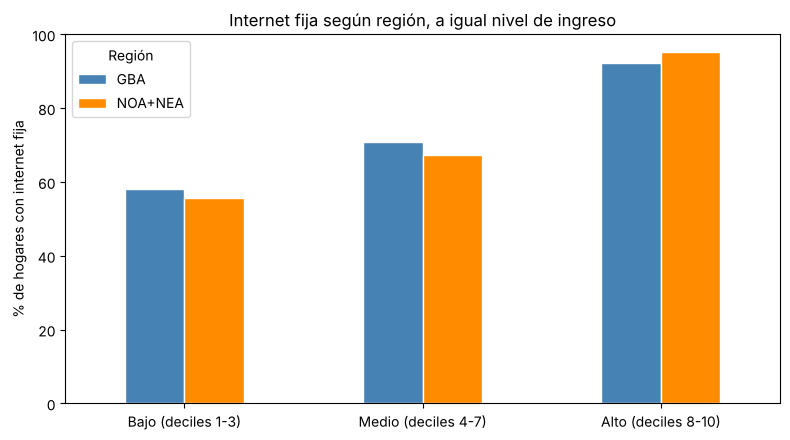

In [16]:
# Grafico: internet fija por region dentro de cada grupo de ingreso
orden_g = ["Bajo (deciles 1-3)", "Medio (deciles 4-7)", "Alto (deciles 8-10)"]
graf = (d3.groupby(["GRUPO_INGRESO", "BLOQUE"], observed=True)["TIENE_INTERNET"].mean().unstack() * 100).reindex(orden_g)
graf.plot(kind="bar", figsize=(8, 4.5), color=["steelblue", "darkorange"], edgecolor="white")
plt.title("Internet fija según región, a igual nivel de ingreso")
plt.ylabel("% de hogares con internet fija"); plt.xlabel(""); plt.xticks(rotation=0); plt.ylim(0, 100)
plt.legend(title="Región"); plt.tight_layout(); plt.show()

**Cómo se lee:** el acceso a internet es casi igual en todas las regiones (entre 72 % y 76 %) y las diferencias entre GBA y NOA/NEA, a igual ingreso, son chicas y **no significativas** (p mayor a 0,05 en los tres grupos). **La hipótesis 3 se rechaza**: en estos datos el territorio no explica el acceso; pesan el ingreso y la educación.

## Matriz de correlación
Resume todas las relaciones en una sola tabla. Se usa la correlación de **Spearman**, que sirve para variables ordenadas (educación, decil) y 0/1. Va de -1 a 1: cuanto más cerca de 1 (o -1), más fuerte la relación; cerca de 0, no hay relación.

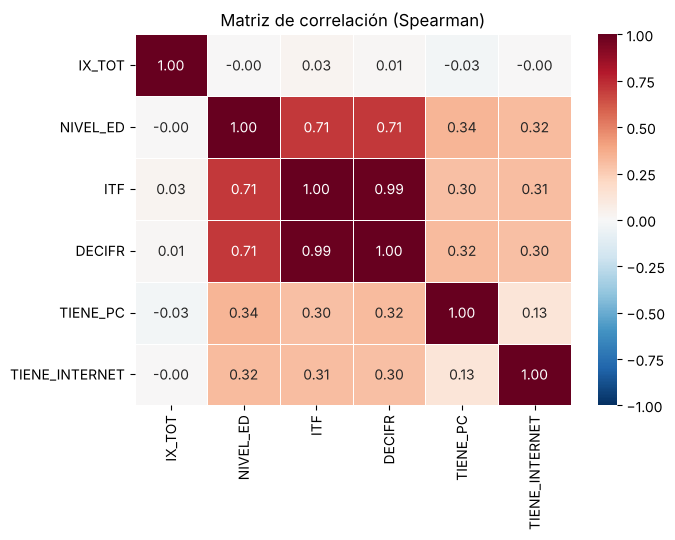

In [17]:
variables = ["IX_TOT", "NIVEL_ED", "ITF", "DECIFR", "TIENE_PC", "TIENE_INTERNET"]
corr = df[variables].corr(method="spearman").round(2)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Matriz de correlación (Spearman)")
plt.tight_layout(); plt.show()

**Cómo se lee:**
- Educación, ingreso y decil se relacionan con tener PC e internet (correlaciones de 0,30 a 0,34).
- El **tamaño del hogar** (`IX_TOT`) no se relaciona con nada (valores cerca de 0).
- Educación e ingreso están muy relacionados entre sí (0,71): en estos datos no se puede separar del todo el efecto de cada uno.

## Resumen de resultados
| Hipótesis | Resultado |
|---|---|
| H1: más educación → más acceso | **Se confirma** (p < 0,001; V ≈ 0,33-0,35) |
| H2: más ingreso → más acceso | **Se confirma** (brecha decil 10 vs 1: 54 pp en PC y 37 pp en internet) |
| H3: a igual ingreso, NOA/NEA tienen menos internet que GBA | **Se rechaza** (diferencias chicas y no significativas) |